### 1. Preprocesarea Datelor si Discretizarea Tintei

In [ ]:
import xgboost as xgb
import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OrdinalEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             confusion_matrix, roc_curve, auc, precision_recall_curve)


housing = pd.read_csv('../L1/AmesHousing.csv', sep='\t')
housing.columns = housing.columns.str.replace(' ', '').str.replace('_', '')


num_cols = housing.select_dtypes(include=np.number).columns
cat_cols = housing.select_dtypes(exclude=np.number).columns
housing[num_cols] = housing[num_cols].fillna(housing[num_cols].median())
housing[cat_cols] = housing[cat_cols].fillna("None")

bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
labels = [0, 1, 2, 3, 4, 5] 
housing['PriceClass'] = pd.cut(housing['SalePrice'], bins=bins, labels=labels, right=False)


encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
housing[cat_cols] = encoder.fit_transform(housing[cat_cols])


X = housing.drop(columns=['SalePrice', 'PriceClass'])
y = housing['PriceClass'].astype(int)

### 2. Train-Test si Compromisul Bias-Varianta

In [ ]:
#10% vs 20% 
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y, test_size=0.10, stratify=y, random_state=42)
X_train_20, X_test_20, y_train_20, y_test_20 = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

X_train_unstrat, X_test_unstrat, y_train_unstrat, y_test_unstrat = train_test_split(X, y, test_size=0.20, random_state=42)

print("Distribuția claselor (20% Stratificat):", np.bincount(y_train_20))
print("Distribuția claselor (20% Nestratificat):", np.bincount(y_train_unstrat))

base_xgb = xgb.XGBClassifier(objective='multi:softprob', num_class=6, random_state=42, eval_metric='mlogloss')

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores_5 = cross_val_score(base_xgb, X, y, cv=cv_5, scoring='f1_macro')
scores_10 = cross_val_score(base_xgb, X, y, cv=cv_10, scoring='f1_macro')

print(f"Macro F1 cu k=5: {scores_5.mean():.4f} (+/- {scores_5.std():.4f})")
print(f"Macro F1 cu k=10: {scores_10.mean():.4f} (+/- {scores_10.std():.4f})")

Distribuția claselor (20% Stratificat): [189 407 830 549 318  51]
Distribuția claselor (20% Nestratificat): [186 417 846 548 303  44]
Macro F1 cu k=5: 0.7369 (+/- 0.0053)
Macro F1 cu k=10: 0.7357 (+/- 0.0366)


### 3. Evaluarea Modelului de Bază & Găsirea Pragului Optim

Acuratețe: 0.7696
Precizie (Macro): 0.7685
Rechemare (Macro): 0.7326
Scorul F1 (Macro): 0.7479


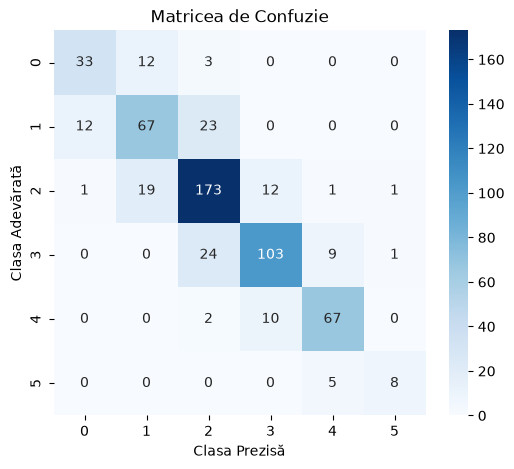

Clasa 0 -> Cel mai bun F1: 0.7477 la pragul de probabilitate: 0.1422
Clasa 1 -> Cel mai bun F1: 0.7149 la pragul de probabilitate: 0.1676
Clasa 2 -> Cel mai bun F1: 0.8121 la pragul de probabilitate: 0.2546
Clasa 3 -> Cel mai bun F1: 0.8043 la pragul de probabilitate: 0.3518
Clasa 4 -> Cel mai bun F1: 0.8500 la pragul de probabilitate: 0.4988
Clasa 5 -> Cel mai bun F1: 0.7742 la pragul de probabilitate: 0.0283


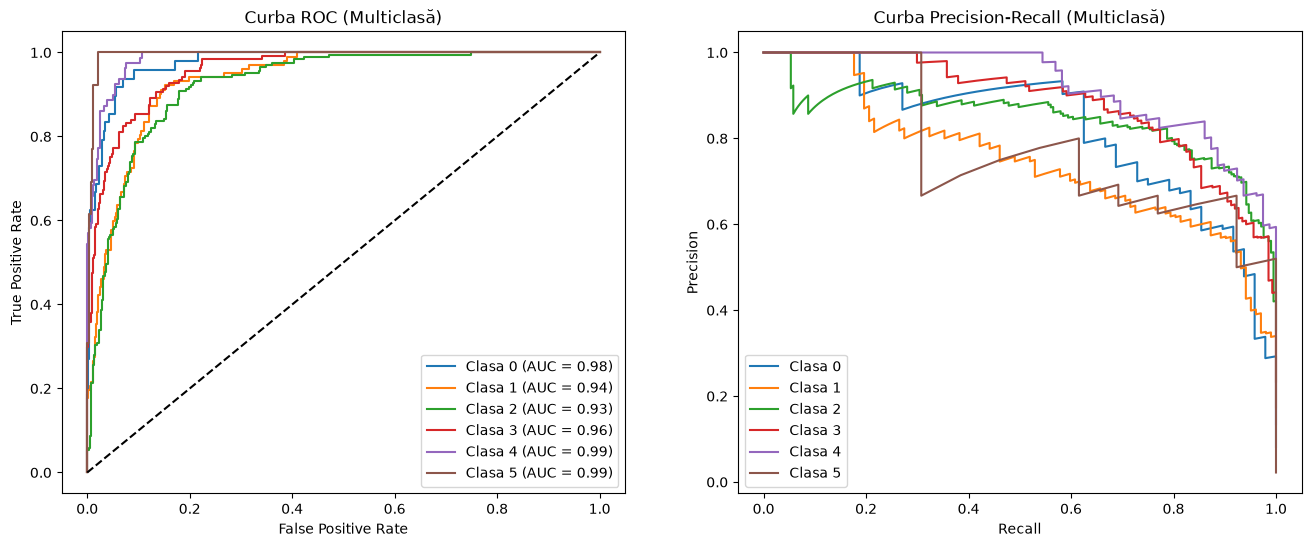

In [ ]:
# Antrenarea modelului
model = xgb.XGBClassifier(objective='multi:softprob', num_class=6, random_state=42)
model.fit(X_train_20, y_train_20)

y_pred = model.predict(X_test_20)
y_proba = model.predict_proba(X_test_20)

# 1. Metrici Standard
print(f"Acuratețe: {accuracy_score(y_test_20, y_pred):.4f}")
print(f"Precizie (Macro): {precision_score(y_test_20, y_pred, average='macro'):.4f}")
print(f"Rechemare (Macro): {recall_score(y_test_20, y_pred, average='macro'):.4f}")
print(f"Scorul F1 (Macro): {f1_score(y_test_20, y_pred, average='macro'):.4f}")

# 2. Matricea de Confuzie
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test_20, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Matricea de Confuzie")
plt.ylabel('Clasa Adevarata')
plt.xlabel('Clasa Prezisă')
plt.show()


y_test_bin = label_binarize(y_test_20, classes=[0, 1, 2, 3, 4, 5])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for i in range(6):
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    ax1.plot(fpr, tpr, label=f'Clasa {i} (AUC = {auc(fpr, tpr):.2f})')
    
    # Precision-Recall Curve & Thresholds
    precision, recall, thresholds = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
    ax2.plot(recall, precision, label=f'Clasa {i}')
  
    f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)
    best_idx = np.argmax(f1_scores)
    
  
    if best_idx < len(thresholds):
        print(f"Clasa {i} -> Cel mai bun F1: {f1_scores[best_idx]:.4f} la pragul de probabilitate: {thresholds[best_idx]:.4f}")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('Curba ROC (Multiclasă)')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend()

ax2.set_title('Curba Precision-Recall (Multiclasă)')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.show()

### 4. Arbori, Importanta Caracteristicilor si Interpretarea lor

c:\Projects 2\ML\venv\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


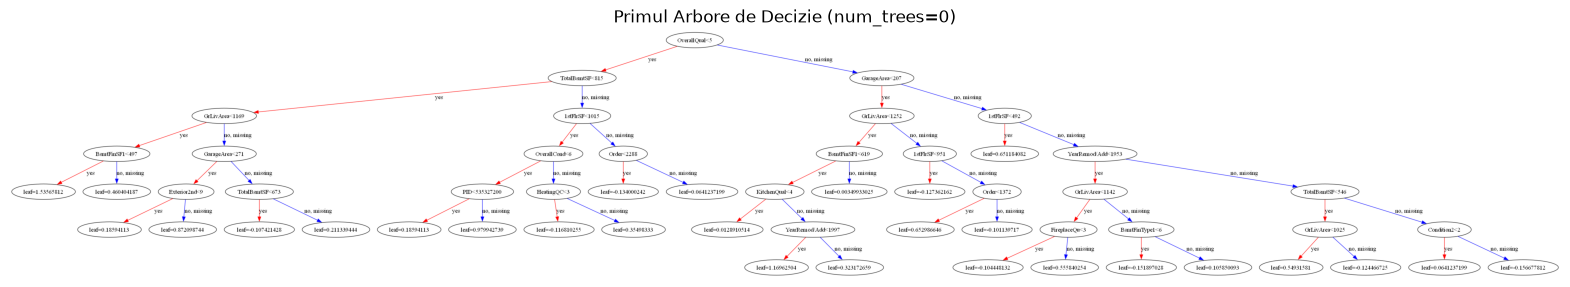

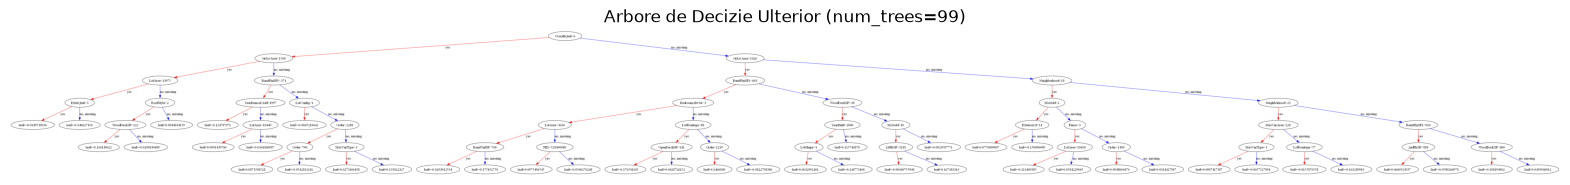

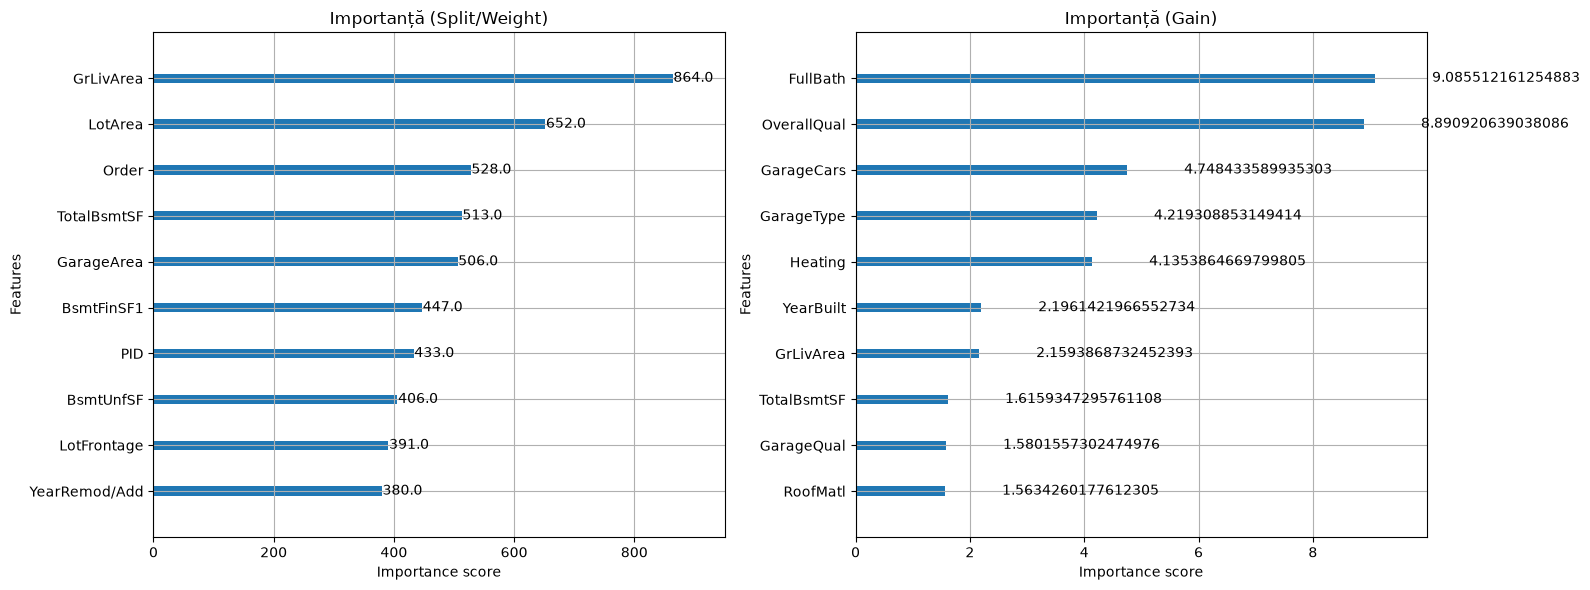

In [ ]:

plt.rcParams['figure.figsize'] = [20, 10]

# 1. Primul arbore
xgb.plot_tree(model, num_trees=0)
plt.title("Primul Arbore de Decizie (num_trees=0)")
plt.show()

# 2. Ultimul arbore (ex. 99 pt n_estimators 100)
xgb.plot_tree(model, num_trees=99)
plt.title("Arbore de Decizie Ulterior (num_trees=99)")
plt.show()

# Split vs Gain
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

xgb.plot_importance(model, importance_type='weight', max_num_features=10, ax=ax1, title="Importanta (Split/Weight)")
xgb.plot_importance(model, importance_type='gain', max_num_features=10, ax=ax2, title="Importanta (Gain)")
plt.tight_layout()
plt.show()

### 5. Optimizarea Hiperparametrilor: Manual vs. Optuna

In [ ]:


model_fast = xgb.XGBClassifier(learning_rate=0.5, max_depth=3, random_state=42).fit(X_train_20, y_train_20)
model_deep = xgb.XGBClassifier(learning_rate=0.05, max_depth=10, random_state=42).fit(X_train_20, y_train_20)

print(f"F1 Macro (Invatare Rapidă - 0.5): {f1_score(y_test_20, model_fast.predict(X_test_20), average='macro'):.4f}")
print(f"F1 Macro (Arbori Adanci - 0.05): {f1_score(y_test_20, model_deep.predict(X_test_20), average='macro'):.4f}")

#optuna
def objective(trial):
    param = {
        'objective': 'multi:softprob',
        'num_class': 6,
        'eval_metric': 'mlogloss',
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'n_estimators': trial.suggest_int('n_estimators', 50, 300)
    }
    
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    temp_model = xgb.XGBClassifier(**param, random_state=42)
    scores = cross_val_score(temp_model, X_train_20, y_train_20, cv=cv, scoring='f1_macro')
    
    return scores.mean()

# Folosim TPESampler
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)


study.optimize(objective, n_trials=15) 

print("\nCei mai buni parametri gasiti de Optuna:")
print(study.best_params)
print(f"Cel mai bun scor CV Macro F1: {study.best_value:.4f}")

# Graficele interactive Optuna
fig_hist = optuna.visualization.plot_optimization_history(study)
fig_param = optuna.visualization.plot_param_importances(study)

fig_hist.show()
fig_param.show()

[I 2026-11-04 23:14:14,347] A new study created in memory with name: no-name-5971d05a-6124-46c0-95b8-8fb7de303f66


F1 Macro (Învățare Rapidă - 0.5): 0.7097
F1 Macro (Arbori Adânci - 0.05): 0.7368


[I 2026-11-04 23:14:17,608] Trial 0 finished with value: 0.5800539491493172 and parameters: {'learning_rate': 0.008468008575248327, 'max_depth': 10, 'subsample': 0.8659969709057025, 'colsample_bytree': 0.7993292420985183, 'n_estimators': 89}. Best is trial 0 with value: 0.5800539491493172.
[I 2026-11-04 23:14:19,965] Trial 1 finished with value: 0.3502794269941516 and parameters: {'learning_rate': 0.0024345423962016913, 'max_depth': 3, 'subsample': 0.9330880728874675, 'colsample_bytree': 0.8005575058716043, 'n_estimators': 227}. Best is trial 0 with value: 0.5800539491493172.
[I 2026-11-04 23:14:22,928] Trial 2 finished with value: 0.08716651426701866 and parameters: {'learning_rate': 0.001124579825911934, 'max_depth': 10, 'subsample': 0.9162213204002109, 'colsample_bytree': 0.6061695553391381, 'n_estimators': 95}. Best is trial 0 with value: 0.5800539491493172.
[I 2026-11-04 23:14:24,713] Trial 3 finished with value: 0.1813937643156974 and parameters: {'learning_rate': 0.0028465263577


Cei mai buni parametri găsiți de Optuna:
{'learning_rate': 0.11676436132723145, 'max_depth': 4, 'subsample': 0.6193465489176402, 'colsample_bytree': 0.8174883296134541, 'n_estimators': 228}
Cel mai bun scor CV Macro F1: 0.7159
